# Coding Assignment 9: Gradient, Hessian, and PCA

---
## What You'll Learn
- Compute gradients numerically and symbolically
- Build and interpret the Hessian matrix at a critical point
- Run PCA from scratch using the spectral theorem
- **Milestone:** PCA on token embeddings — find the 2D subspace that explains the most variance

## Estimated Time: 2–3 hours
---


## Start here: how to work through this notebook

You do not need to remember an earlier programming course. Work one small step
at a time. The mathematics is the goal; the programming examples are here to
help you express it.

1. Save your own copy of the notebook. A **cell** is one block of text or code.
   Click a code cell and press **Shift+Enter** to run it. Run cells from the top
   down: later cells use names created by earlier cells.
2. Run the setup cell first. `import numpy as np` makes NumPy's array tools
   available under the short name `np`.
3. Read the explanation and run the small practice example before attempting
   the corresponding task. Practice cells are supplied; you may experiment
   with them, but restore them before the final run.
4. Edit only the requested task or response. `#` begins a comment. `pass` is a
   placeholder that does nothing; a function ending at `pass` returns `None`
   (no result). Replace it with your calculation and a `return` statement.
5. Running a cell containing `def` stores the function; it does not call it.
   After editing the definition, run that cell again, then run its check cell.
   A successful `assert` may print nothing. A skipped check is not a pass:
   if a result is still `None`, the task is unfinished.
6. If a check fails, stop there. Read the last line of the error, print the
   relevant array's `.shape`, and fix this task before running cells that need it.
   Errors below an unfinished task are expected and are not separate failures.
7. Save, restart the kernel/runtime (the Python session), and run everything
   from the beginning once your work is complete. This catches accidental use
   of a value left over from an earlier attempt.

**Reading code:** `=` stores a value; `==` compares values; `@` multiplies
matrices; `*` multiplies entries or scales an array; `**2` squares entries.
Python indices start at **0**: mathematical entry $a_{1,1}$ is `A[0, 0]`.
`A.shape` is `(number_of_rows, number_of_columns)`, `A.ndim` counts dimensions,
and `A.T` transposes a matrix. An ordinary vector has shape `(n,)`.

**If you get stuck:** record the function name, the smallest input that fails,
its shape, the expected mathematical result, and the last line of the error.
Include these when asking for help. You do not need to rewrite the whole cell.

**Plan your time:** if Python is new to you, allow extra time beyond the
headline estimate and work in several short sessions. Start with setup and
the practice example; then finish one task at a time.

More worked examples and an error-message checklist: [Python and NumPy help](`mt_utils.py` / `mini_transformer.py` in this folder).


### Files, dependencies, and what you are expected to edit

Save this notebook and download the supplied helper
`mt_utils.py` (same folder as this notebook)
using GitHub's **Download raw file** button. Put it beside the notebook; in
Colab, upload it through the Files panel before setup. This is a read-only
instructor helper for making reproducible toy data. Do not edit or submit it.
If Python cannot find it, check the filename and working folder first.

The notebook uses NumPy and Matplotlib. Colab normally provides these.
Locally, install missing packages in the notebook's environment with
`%pip install numpy matplotlib`, then
restart the kernel. Run this installation command only if setup reports a
missing package.

Read the task guides below to distinguish **supplied demonstrations** from
**code you edit**. For a supplied implementation, run the code and trace its intermediate
values. Only fill placeholders explicitly identified as your task. Keep function names and arguments unchanged.
Write your observations in a Markdown cell below each experiment.

**Grading (20 points):** numerical gradient, 4; numerical Hessian, 4;
supplied PCA fit/transform, 4; your reconstruction's coordinate combination,
4; restoring the stored mean to every row, 4. The first 12 points check the
supplied implementations; leave those definitions in the submitted notebook.
The last 8 points require completing `PCAWithReconstruct.reconstruct`.
The grader checks numerical values, not just array shapes. The optional spread
experiment and portfolio copy add no autograder points.

Submit exactly **one completed `.ipynb` notebook**. You do not need to submit
`mt_utils.py`, `mini_transformer.py`, or the saved plot images for this homework.
In Colab, use **File → Download → Download .ipynb** after saving your work.


In [1]:
# Supplied practice: run this unchanged, then trace the result by hand.
import numpy as np

def double_and_total(values):
    values = np.asarray(values, dtype=float)  # turn a list into a numerical array
    doubled = 2 * values                     # one intermediate calculation
    total = np.sum(doubled)                   # add all entries
    return doubled, total                    # send two results back to the caller

practice_vector, practice_total = double_and_total([1, -2, 3])
print(practice_vector)        # [ 2. -4.  6.]
print(practice_vector.shape)  # (3,)
print(practice_total)         # 4.0
assert practice_total == 4.0


[ 2. -4.  6.]
(3,)
4.0


## Setup


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sys; sys.path.insert(0, ".")
import mt_utils
np.set_printoptions(precision=4, suppress=True)
print("Setup complete.")


Setup complete.


---
## Part 1: Python Basics — Numerical Differentiation

The **finite difference** approximation to the derivative is:
$$f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}$$

This is the **centered difference** formula, which is $O(h^2)$ accurate.


### Supplied walkthrough: change one coordinate

`f` is a function passed as an argument; `f(x_plus)` calls it. A `lambda` is
a short function definition. `range(len(x))` visits indices `0` through `n-1`.
`x.copy()` makes an independent array: editing `x_plus[i]` must not change `x`.
Trace `i=0` on `x=[1., 2.]`: only the first coordinate changes by `h`.
The returned gradient has shape `(n,)`, one partial derivative per coordinate.


In [3]:
# 1.1 Numerical gradient of a scalar function
def numerical_gradient(f, x, h=1e-5):
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x_plus  = x.copy(); x_plus[i]  += h
        x_minus = x.copy(); x_minus[i] -= h
        grad[i] = (f(x_plus) - f(x_minus)) / (2 * h)
    return grad

# Test: f(x) = x1^2 + 2*x2^2 + x1*x2, gradient = [2x1+x2, 4x2+x1]
f = lambda x: x[0]**2 + 2*x[1]**2 + x[0]*x[1]
x0 = np.array([1.0, 2.0])

grad_num = numerical_gradient(f, x0)
grad_true = np.array([2*x0[0] + x0[1],   4*x0[1] + x0[0]])   # analytic

print("Numerical gradient:", grad_num.round(6))
print("Analytic gradient: ", grad_true.round(6))
print("Error:", np.linalg.norm(grad_num - grad_true))


Numerical gradient: [4. 9.]
Analytic gradient:  [4. 9.]
Error: 6.428222816451783e-11


**Worked example:** Trace and run `numerical_hessian(f, x, h=1e-4)` using the formula $H_{ij} = \frac{f(x+he_i+he_j) - f(x+he_i-he_j) - f(x-he_i+he_j) + f(x-he_i-he_j)}{4h^2}$.


### Supplied Hessian: run, trace, and check

The implementation is already provided. The nested loops visit every pair
`(i, j)`; `H[i, j]` stores one second partial derivative. For input shape `(n,)`,
the output is `(n, n)`. Trace the four shifted points first with `i=0, j=1`,
then with `i=j=0`; two changes to the same entry add to a shift of `2*h`.
Check symmetry and compare with the displayed exact Hessian. Do not make `h`
arbitrarily tiny: subtraction and roundoff eventually reduce accuracy.


In [4]:
def numerical_hessian(f, x, h=1e-4):
    n = len(x)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            xpp = x.copy(); xpp[i] += h; xpp[j] += h
            xpm = x.copy(); xpm[i] += h; xpm[j] -= h
            xmp = x.copy(); xmp[i] -= h; xmp[j] += h
            xmm = x.copy(); xmm[i] -= h; xmm[j] -= h
            H[i, j] = (f(xpp) - f(xpm) - f(xmp) + f(xmm)) / (4 * h**2)
    return H

H_num = numerical_hessian(f, x0)
H_true = np.array([[2., 1.], [1., 4.]])   # analytic Hessian of f above
print("Numerical Hessian:\n", H_num.round(6))
print("Analytic Hessian:\n", H_true)
print("Error:", np.linalg.norm(H_num - H_true))
assert np.allclose(H_num, H_true, atol=1e-6)
print("numerical_hessian: passed")


Numerical Hessian:
 [[2. 1.]
 [1. 4.]]
Analytic Hessian:
 [[2. 1.]
 [1. 4.]]
Error: 1.1391697422930569e-07
numerical_hessian: passed


---
## Part 2: Linear Algebra — PCA from Scratch

### 2.1 The PCA Algorithm

Principal Component Analysis (PCA) finds the orthonormal directions
of maximum variance in a dataset:

1. **Center** the data: $X_c = X - \bar{x}^\top$
2. **Compute** the covariance matrix: $\Sigma = \frac{1}{n-1} X_c^\top X_c$
3. **Eigendecompose** $\Sigma = V \Lambda V^\top$ (spectral theorem — $\Sigma$ is symmetric!)
4. **Project** onto top $k$ eigenvectors: $Z = X_c V_k$

The eigenvectors (principal components) are ordered by decreasing eigenvalue.


### Reading a class before using PCA

A **class** groups functions with stored data. `pca = PCA(n_components=1)`
creates one object. `self` means “this object”; `self.mean` stores its mean.
`fit` learns directions from the supplied data; `transform` applies those
directions. Call `fit` before `transform`, or use `fit_transform` to do both.

With data `(n, d)`, `self.mean` is `(d,)`, `self.components` is `(k, d)`, and
projected coordinates are `(n, k)`. A method is a function inside a class;
you do not explicitly pass `self` when calling `pca.transform(X)`.


In [5]:
# 2.1 PCA class
class PCA:
    def __init__(self, n_components):
        self.k = n_components
        self.components = None   # (k, d) — each row is a principal component
        self.mean = None
        self.explained_variance_ratio = None

    def fit(self, X):
        n, d = X.shape
        self.mean = X.mean(axis=0)
        Xc = X - self.mean                        # center
        Sigma = Xc.T @ Xc / (n - 1)              # covariance (d x d)
        evals, evecs = np.linalg.eigh(Sigma)      # eigenvectors as columns
        # Sort descending
        idx = np.argsort(-evals)
        evals, evecs = evals[idx], evecs[:, idx]
        self.components = evecs[:, :self.k].T     # (k, d)
        self.explained_variance_ratio = evals[:self.k] / evals.sum()
        return self

    def transform(self, X):
        Xc = X - self.mean
        return Xc @ self.components.T             # (n, k)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

# Test on synthetic data
rng = np.random.default_rng(7)
# 2D data that's actually 1D (a line) with noise
t = rng.standard_normal(100)
X_synth = np.column_stack([2*t + 0.1*rng.standard_normal(100),
                            t   + 0.1*rng.standard_normal(100)])

pca = PCA(n_components=1)
Z = pca.fit_transform(X_synth)
print("Input shape:", X_synth.shape)
print("Projected shape:", Z.shape)
print("Explained variance ratio:", pca.explained_variance_ratio.round(4))
print("(Should be close to 1.0 — data is almost 1D)")


Input shape: (100, 2)
Projected shape: (100, 1)
Explained variance ratio: [0.9977]
(Should be close to 1.0 — data is almost 1D)


**Your turn:** Add a `reconstruct(self, Z)` method to PCA that maps the $k$-dimensional projection back to the original $d$-dimensional space.


### Your edit: reconstruct in the original feature coordinates

The subclass `PCAWithReconstruct(PCA)` inherits the supplied PCA methods.
Edit only the body of `reconstruct`:

1. Multiply `Z`, with shape `(m, k)`, by the stored directions
   `self.components`, with shape `(k, d)`. Each row of `Z` gives the coefficients
   for a linear combination of those direction rows. The result is `(m, d)`.
2. Add `self.mean`, with shape `(d,)`, to **every row** of the result. NumPy
   repeats this addition across rows automatically; this is called broadcasting.
   Use the mean saved during `fit`, not the mean of `Z` or of the new rows.
3. Return the result. Keep the stored directions and mean available for later calls.

Here `m` is the number of rows to reconstruct; it need not equal the number of
rows used to fit the PCA object. Inputs are two-dimensional numerical arrays
with `1 <= k <= d`; you do not need to implement invalid-input handling.

**Tiny example to trace:** suppose the retained direction is `(0, 1)` and the
stored mean is `(10, 20)`. Coordinates `2` and `-3` give centered rows `(0, 2)`
and `(0, -3)`. Adding the mean gives `(10, 22)` and `(10, 17)`.
A zero coordinate reconstructs the mean `(10, 20)`.

With all directions retained, reconstruction agrees with the original rows up
to rounding. Fewer directions generally leave some reconstruction error.


In [6]:
class PCAWithReconstruct(PCA):
    def reconstruct(self, Z):
        # Combine the projection with principal directions and add the mean
        return Z @ self.components + self.mean

pca2 = PCAWithReconstruct(n_components=1)
Z2 = pca2.fit_transform(X_synth)
X_rec = pca2.reconstruct(Z2)

if X_rec is not None:
    err = np.linalg.norm(X_synth - X_rec, 'fro')
    print(f"Reconstruction error (rank-1): {err:.4f}")
    # Compare squared reconstruction error with the discarded fraction.
    var_lost = 1 - pca2.explained_variance_ratio.sum()
    total_squared = np.linalg.norm(X_synth - pca2.mean, "fro")**2
    print(f"Variance not captured: {var_lost:.4f}")
    print(f"Fraction of squared variation lost: {err**2 / total_squared:.4f}")
else:
    print("NOT COMPLETE: reconstruct returned None. Replace pass and return the reconstructed rows.")


Reconstruction error (rank-1): 0.9517
Variance not captured: 0.0023
Fraction of squared variation lost: 0.0023


In [7]:
# Supplied checks: run after completing reconstruct.
# Set a tiny fitted state so the expected values can be checked by hand.
check_pca = PCAWithReconstruct(n_components=1)
check_pca.components = np.array([[0., 1.]])
check_pca.mean = np.array([10., 20.])
check_result = check_pca.reconstruct(np.array([[2.], [-3.], [0.]]))
assert check_result is not None
assert np.asarray(check_result).shape == (3, 2), "Each coordinate row must become a feature row."
assert np.allclose(check_result, [[10., 22.], [10., 17.], [10., 20.]]), \
    "Combine the stored direction rows, then add the stored mean to every row."

# All feature directions retained: no information should be lost.
check_X = np.array([[8., 19.], [10., 23.], [12., 18.], [14., 24.]])
check_full = PCAWithReconstruct(n_components=2)
check_Z = check_full.fit_transform(check_X)
assert np.allclose(check_full.reconstruct(check_Z), check_X), \
    "With all directions retained, reconstruction must recover the input."
print("reconstruct: hand example and full reconstruction passed")


reconstruct: hand example and full reconstruction passed


### 2.2 Scree Plot

A **scree plot** shows explained variance vs. number of components.
The "elbow" suggests where to truncate.


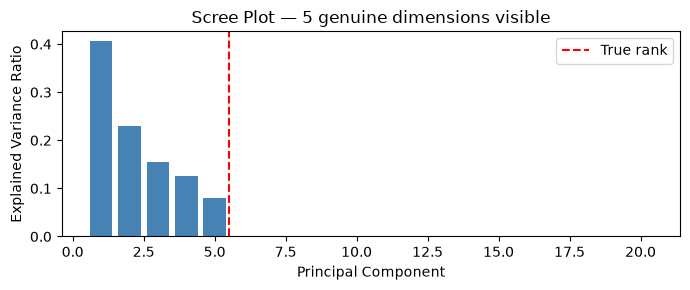

In [8]:
# 2.2 Scree plot
rng = np.random.default_rng(412)
d_big = 20
# Construct data with genuine 5D structure
W_true = rng.standard_normal((100, 5)) @ rng.standard_normal((5, d_big))
X_big = W_true + 0.1 * rng.standard_normal((100, d_big))

pca_full = PCA(n_components=d_big).fit(X_big)

plt.figure(figsize=(7, 3))
plt.bar(range(1, d_big+1), pca_full.explained_variance_ratio, color='steelblue')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot — 5 genuine dimensions visible')
plt.axvline(5.5, color='red', linestyle='--', label='True rank')
plt.legend(); plt.tight_layout()
plt.savefig('hw8_scree.png', dpi=100); plt.show()


---
## Part 3: DS/AI Application — Gradient of a Loss Function

### 3.1 Gradient of Mean Squared Error

For the linear model $\hat{y} = Xw$, the MSE loss is:
$$\mathcal{L}(w) = \frac{1}{n}\|Xw - y\|^2$$

The gradient is:
$$\nabla_w \mathcal{L} = \frac{2}{n} X^\top(Xw - y)$$

Setting this to zero gives the **normal equations**: $X^\top X w = X^\top y$.


In [9]:
# 3.1 Gradient of MSE loss — verify numerically vs analytically
rng = np.random.default_rng(42)
n, d_feat = 30, 4
X_reg = rng.standard_normal((n, d_feat))
w_true = np.array([1., -2., 0.5, 3.])
y_reg = X_reg @ w_true + 0.1 * rng.standard_normal(n)

def mse_loss(w):
    return np.mean((X_reg @ w - y_reg)**2)

def mse_gradient(w):
    return 2/n * X_reg.T @ (X_reg @ w - y_reg)

w_test = rng.standard_normal(d_feat)
grad_analytic = mse_gradient(w_test)
grad_numeric  = numerical_gradient(mse_loss, w_test)

print("Analytic gradient: ", grad_analytic.round(6))
print("Numeric gradient:  ", grad_numeric.round(6))
print("Match:", np.allclose(grad_analytic, grad_numeric, atol=1e-5))

# Solve normal equations
w_opt = np.linalg.solve(X_reg.T @ X_reg, X_reg.T @ y_reg)
print(f"Optimal w: {w_opt.round(4)}")
print(f"True    w: {w_true}")


Analytic gradient:  [-1.6022  1.4923 -4.3601 -3.4092]
Numeric gradient:   [-1.6022  1.4923 -4.3601 -3.4092]
Match: True
Optimal w: [ 1.005  -2.0079  0.5063  2.9572]
True    w: [ 1.  -2.   0.5  3. ]


---
## Part 4: Mini-Transformer Milestone — PCA on Token Embeddings

### Week 9 Milestone

Run PCA on the 6-token embedding matrix to find its 2D structure.
Plot the tokens in 2D PCA space and annotate with their names.


Embedding matrix shape: (6, 8)
Explained variance ratio: [0.5169 0.3038]
Total variance captured: 0.8206


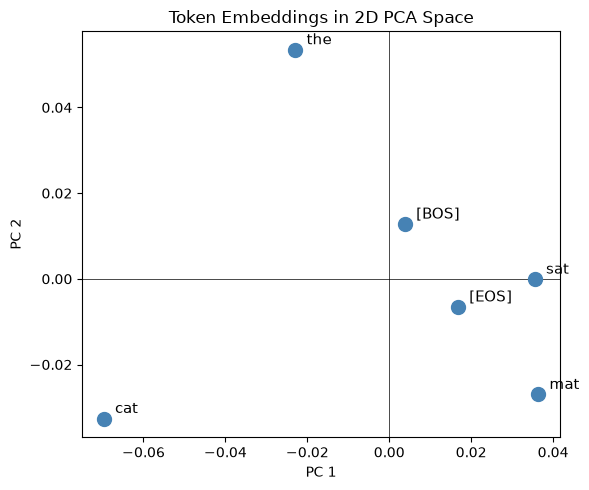

In [10]:
# Milestone: PCA on token embeddings
mt_utils.set_seed(412)
vocab = {"[BOS]": 0, "the": 1, "cat": 2, "sat": 3, "mat": 4, "[EOS]": 5}
E = mt_utils.make_embedding_matrix(6, 8)   # (6, 8)

pca_embed = PCA(n_components=2)
E_2d = pca_embed.fit_transform(E)

print("Embedding matrix shape:", E.shape)
print("Explained variance ratio:", pca_embed.explained_variance_ratio.round(4))
print("Total variance captured:", pca_embed.explained_variance_ratio.sum().round(4))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(E_2d[:, 0], E_2d[:, 1], s=100, c='steelblue', zorder=3)
for word, idx in vocab.items():
    ax.annotate(word, E_2d[idx], textcoords='offset points',
                xytext=(8, 4), fontsize=11)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax.set_title("Token Embeddings in 2D PCA Space")
ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
plt.tight_layout()
plt.savefig('hw8_token_pca.png', dpi=100); plt.show()


### Optional experiment: gradient of spread loss

`E.ravel()` lists all entries in one vector; `reshape(6, 8)` reverses that
operation. The supplied loss is **negative** total squared distance. Call
the supplied `numerical_gradient` with `spread_loss` and `E_flat`; replace
`None` with the result. Its shape should match `E_flat.shape`.
The **negative** gradient increases spread locally because it decreases this
negative loss. Compare `spread_loss(E_flat - 0.001 * grad_spread)` with the
original value; do not interpret the positive gradient as increasing spread.


In [11]:
# L(E) = -sum of pairwise squared distances between embeddings (we want them spread out)
# Then check your gradient numerically.

def spread_loss(E_flat):
    E_mat = E_flat.reshape(6, 8)
    total = 0.0
    for i in range(6):
        for j in range(i+1, 6):
            diff = E_mat[i] - E_mat[j]
            total += np.dot(diff, diff)
    return -total   # negative because we want to maximize spread

E_flat = E.ravel()
grad_spread = numerical_gradient(spread_loss, E_flat)

if grad_spread is not None:
    print("Gradient shape:", grad_spread.shape)
    print("Gradient norm:", np.linalg.norm(grad_spread).round(4))


Gradient shape: (48,)
Gradient norm: 1.5171


### Project checkpoint: PCA reconstruction

Center feature rows, keep a few principal coordinates, and reconstruct an approximation. This is a diagnostic of the embedding geometry.

1. Download **this assignment's** `student/mini_transformer.py` and keep it
   beside the notebook. In Colab, upload it using the Files panel. It contains
   completed earlier checkpoints, so a missing older submission will not block you.
2. Open the file and search for **THIS WEEK**. Copy the completed reconstruct method from your notebook into the matching method below. Keep the class line and indentation; do not paste plot/setup cells.
3. Save the file. Run the reload/check cell below. `mt.name(...)` calls the
   version saved in your module; notebook definitions do not automatically move there.
4. Run the comparison with your notebook result. A match confirms the saved
   component can reproduce that calculation outside the notebook. Explain what
   its input rows and output entries represent in one or two sentences.

Keep `mini_transformer.py` with your project files. **Submit the notebook as
before; this checkpoint adds no graded implementation or extra the course portal file
requirement.** The instructor helper `mt_utils.py` is still read-only. Download
your edited project file before leaving Colab. Model code never belongs in
`mt_utils.py`.

If the companion file is absent, the cell reports **NOT RUN**, not a pass.
This keeps the existing notebook-only grading path independent of the optional
portfolio copy. Download the file and rerun to check your saved project.


In [12]:
import importlib
try:
    import mini_transformer as mt
except ModuleNotFoundError as error:
    if error.name != "mini_transformer":
        raise  # report a genuinely missing dependency inside the file
    print("Project checkpoint NOT RUN: place this assignment's mini_transformer.py beside the notebook.")
    print("This is a portfolio check, separate from the graded notebook tasks.")
else:
    mt = importlib.reload(mt)
    mt.check_milestone()

    Z_project = pca2.transform(X_synth)
    # The companion uses the same class: complete reconstruct there, then compare.
    project_pca = mt.PCAWithReconstruct(n_components=1)
    project_pca.fit(X_synth)
    assert np.allclose(project_pca.reconstruct(project_pca.transform(X_synth)),
                       pca2.reconstruct(Z_project))
    print("Saved project component agrees with the notebook.")


HW11 project checks passed. Continue with the notebook experiment.
Saved project component agrees with the notebook.


### Checklist
- [ ] `numerical_hessian` passes assertion
- [ ] PCA class reconstructs correctly
- [ ] Scree plot shows elbow at 5 components
- [ ] MSE gradient matches numerical gradient
- [ ] Token PCA plot generated
- [ ] (Bonus) Spread loss gradient computed

---
